# 06 · Minería de grafos — SportSmart Perú

¿Qué productos, clientes o categorías están fuertemente conectados y qué comunidades o patrones aparecen?

**Criterio de éxito:** modularidad > 0,3 en la red producto-producto.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from src.models import grafos
from src.data.estilo_graficos import AGUA, AZUL, GRIS, NARANJA, SUPERFICIE, TINTA, aplicar_estilo, guardar, numero
aplicar_estilo()
res = grafos.main()
NOMBRES = {0: 'Running y fútbol', 1: 'Training y yoga', 2: 'Outdoor'}; COLORES = {0: AZUL, 1: NARANJA, 2: AGUA}

## 1. El grafo cliente-producto

Relaciones de la propuesta:

- **compra:** el cliente compró el producto en un pedido válido.
- **recomienda:** el cliente dio 4 o 5 estrellas en un pedido con un solo producto. El dataset no registra recomendaciones explícitas, y solo en esos pedidos se sabe a qué producto se refiere la reseña.

In [2]:
pd.Series({**res['heterogeneo'], **res['producto_producto']}, name='valor').to_frame()

,valor
clientes,7812.0000
productos,321.0000
aristas_compra,84614.0000
aristas_recomienda,9522.0000
resenas_un_producto,12962.0000
pct_recomienda,73.5000
umbral_pedidos,5.0000
nodos,271.0000
aristas,3907.0000
densidad,0.1068


## 2. Comunidades de productos

Dos productos se conectan si coinciden en al menos 5 pedidos. Se compara con redes construidas barajando los productos entre pedidos, que conservan el tamaño de las canastas y la popularidad de cada producto.

In [3]:
co = res['comunidades']; print({k: co[k] for k in ('n', 'modularidad', 'meta', 'cumple_meta', 'estabilidad', 'referencia_azar')})
pd.DataFrame(co['perfil'])[['comunidad', 'productos', 'ingresos_pct', 'subcategorias_principales']]

{'n': 3, 'modularidad': 0.356, 'meta': 0.3, 'cumple_meta': True, 'estabilidad': {'modularidad_media': 0.355, 'modularidad_min': 0.352, 'ari_medio': 0.963}, 'referencia_azar': {'modularidad_media': 0.169, 'modularidad_max': 0.178, 'repeticiones': 10}}


,comunidad,productos,ingresos_pct,subcategorias_principales
0,0,114,48.6,"[Chimpunes, Muñequera, Pelota, Zapatillas runn..."
1,1,99,32.5,"[Zapatillas training, Top deportivo, Banda elá..."
2,2,58,13.1,"[Mochila, Gorra, Jogger, Casaca cortaviento]"


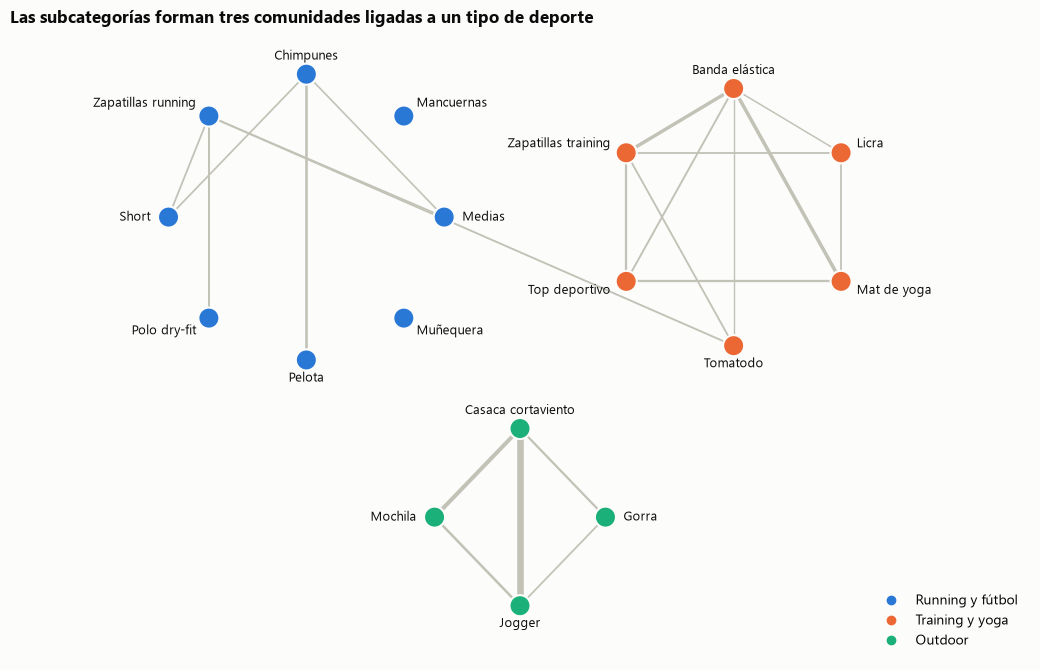

In [4]:
sc = res['subcategorias']; l = pd.DataFrame(sc['lift']); com = sc['comunidad']
G = nx.Graph()
for a, b in zip(*np.triu_indices(len(l), 1)):
    x, y = l.index[a], l.columns[b]
    if x in com and y in com and l.iat[a, b] >= 1.5:
        G.add_edge(x, y, weight=float(l.iat[a, b]))
centros = {0: (-1.55, .35, 1.0), 1: (1.55, .35, .9), 2: (0, -1.75, .62)}; pos = {}
G.add_nodes_from(com)
for c, (cx, cy, r) in centros.items():
    miembros = sorted(n for n in com if com[n] == c)
    for i, n in enumerate(miembros):
        ang = np.pi / 2 - 2 * np.pi * i / len(miembros); pos[n] = (cx + r * np.cos(ang), cy + r * np.sin(ang))
fig, ax = plt.subplots(figsize=(10.5, 6.8)); ax.grid(False); ax.axis('off')
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=GRIS, width=[.5 + d['weight'] / 3 for *_, d in G.edges(data=True)])
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=230, node_color=[COLORES[com[n]] for n in G.nodes], edgecolors=SUPERFICIE, linewidths=1.5)
for n, (x, y) in pos.items():
    cx, cy, _ = centros[com[n]]; dx, dy = x - cx, y - cy; h = np.hypot(dx, dy)
    ax.annotate(n, (x, y), xytext=(13 * dx / h, 13 * dy / h), textcoords='offset points', ha='left' if dx > .15 else 'right' if dx < -.15 else 'center', va='center', fontsize=9.5, color=TINTA)
ax.set_xlim(-3.7, 3.7); ax.set_ylim(-2.75, 1.65)
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=COLORES[i], label=NOMBRES[i]) for i in NOMBRES], loc='lower right')
ax.set_title('Las subcategorías forman tres comunidades ligadas a un tipo de deporte', loc='left')
guardar(fig, 'grafo_subcategorias')

## 3. Clientes relacionados

Cada cliente se asigna a la comunidad donde compra más, y se busca al cliente con compras más parecidas (similitud de coseno).

{'clientes_con_3_o_mas_items': 5648, 'pct_concentrado_60': 85.8, 'pct_por_comunidad': {'0': 55.5, '1': 35.1, '2': 9.4}, 'vecino_comparte_deporte_pct': 88.0, 'azar_comparte_deporte_pct': 21.6, 'similitud_coseno_media_vecino': 0.955}


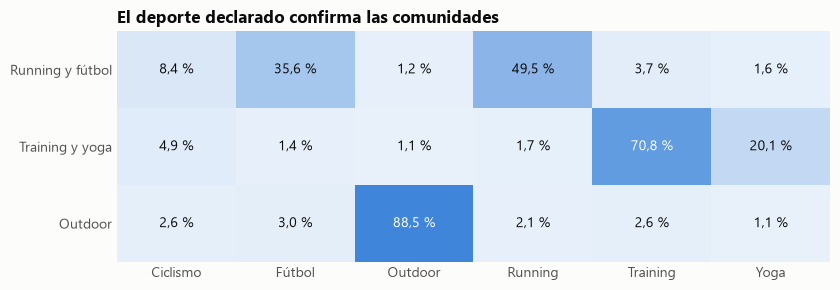

In [5]:
cl = res['clientes_relacionados']; print({k: v for k, v in cl.items() if k != 'deporte_por_comunidad'})
d = pd.DataFrame(cl['deporte_por_comunidad']).T * 100; d.index = [NOMBRES[int(i)] for i in d.index]
fig, ax = plt.subplots(figsize=(8.5, 3)); ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.imshow(d.values, cmap=LinearSegmentedColormap.from_list('az', ['#eaf2fb', AZUL]), aspect='auto', vmin=0, vmax=100)
ax.set_xticks(range(d.shape[1]), d.columns); ax.set_yticks(range(3), d.index)
for i in range(d.shape[0]):
    for j in range(d.shape[1]):
        ax.text(j, i, numero(d.iat[i, j]) + ' %', ha='center', va='center', fontsize=10, color='white' if d.iat[i, j] >= 55 else TINTA)
ax.set_title('El deporte declarado confirma las comunidades')
guardar(fig, 'comunidades_deporte')

## 4. Categorías relacionadas

Lift entre categorías: un valor mayor a 1 indica que coinciden más de lo esperado.

In [6]:
cat = pd.DataFrame(res['categorias']['lift']).astype(float); cat = cat.where(~np.eye(len(cat), dtype=bool))
print('Par con mayor lift:', cat.stack().idxmax(), numero(cat.stack().max(), 2))
cat.round(2)

Par con mayor lift: ('Accesorios', 'Calzado') 1,13


,Accesorios,Calzado,Equipamiento,Ropa inferior,Ropa superior
Accesorios,NaN,1.13,0.65,0.75,0.80
Calzado,1.13,NaN,0.95,1.03,0.78
Equipamiento,0.65,0.95,NaN,0.45,0.36
Ropa inferior,0.75,1.03,0.45,NaN,0.44
Ropa superior,0.80,0.78,0.36,0.44,NaN


## 5. Productos centrales y patrones frecuentes

In [7]:
display(pd.DataFrame(res['productos_centrales'])[['producto_id', 'subcategoria', 'comunidad', 'grado', 'fuerza', 'pagerank', 'intermediacion']])
display(pd.DataFrame(res['recomendaciones_top'])[['producto_id', 'subcategoria', 'resenas', 'recomendaciones', 'pct']])
pd.DataFrame(res['patrones_frecuentes'])

,producto_id,subcategoria,comunidad,grado,fuerza,pagerank,intermediacion
0,P0201,Tomatodo,1,92,812,0.0111,0.0543
1,P0197,Tomatodo,1,95,783,0.0111,0.0384
2,P0199,Tomatodo,1,94,729,0.0103,0.0404
3,P0195,Tomatodo,0,90,738,0.0102,0.0251
4,P0200,Tomatodo,0,90,733,0.0101,0.0240
5,P0198,Tomatodo,1,89,721,0.0101,0.0546
6,P0202,Tomatodo,1,89,719,0.0099,0.0306
7,P0206,Tomatodo,1,84,709,0.0098,0.0457
8,P0205,Tomatodo,1,88,698,0.0098,0.0323
9,P0203,Tomatodo,1,84,687,0.0097,0.0271


,producto_id,subcategoria,resenas,recomendaciones,pct
0,P0005,Zapatillas running,15,14,93.3
1,P0178,Jogger,14,13,92.9
2,P0179,Jogger,13,12,92.3
3,P0092,Casaca cortaviento,12,11,91.7
4,P0234,Mochila,22,20,90.9
5,P0252,Muñequera,21,19,90.5
6,P0130,Polera,28,25,89.3
7,P0210,Gorra,33,29,87.9


,patron,pedidos,soporte_pct,veces_sobre_azar
0,Medias + Tomatodo + Zapatillas running,722,1.197,5.3
1,Short + Tomatodo + Zapatillas running,703,1.166,6.4
2,Medias + Short + Zapatillas running,690,1.144,5.0
3,Medias + Polo dry-fit + Zapatillas running,675,1.119,6.0
4,Tomatodo + Top deportivo + Zapatillas training,649,1.076,8.4
5,Polo dry-fit + Tomatodo + Zapatillas running,646,1.071,7.2
6,Banda elástica + Tomatodo + Zapatillas training,624,1.035,14.8
7,Licra + Tomatodo + Zapatillas training,621,1.030,5.9


## 6. Conclusiones

- **Meta cumplida:** la modularidad es 0,356, muy superior a la de las redes con compras al azar (0,169 en promedio y 0,178 como máximo), lo que confirma que las comunidades no son casuales. Se mantiene al cambiar la semilla (ARI 0,963).
- **Tres comunidades:** Running y fútbol (114 productos, 48,6 % de los ingresos), Training y yoga (99 productos, 32,5 %) y Outdoor (58 productos, 13,1 %).
- **Productos conectores:** los 10 más centrales son Tomatodos, presentes en varias comunidades. Sirven como producto complementario para cualquier canasta.
- **Clientes relacionados:** 85,8 % de los clientes con 3 o más ítems concentra al menos 60 % de sus compras en una comunidad, y 88,0 % comparte deporte con su cliente más parecido, frente a 21,6 % esperado por azar.
- **Categorías:** Calzado y Accesorios son el único par con una afinidad clara (lift 1,13). Los demás están cerca de 1 o por debajo; las relaciones fuertes aparecen por subcategoría.
- **Recomendaciones:** 73,5 % de las 12 962 reseñas de un solo producto son recomendaciones.
- **Patrones frecuentes:** la tríada más común es Medias + Tomatodo + Zapatillas running (722 pedidos, 5,3 veces sobre el azar).

**Acciones:** usar la comunidad para ordenar recomendaciones y campañas por deporte, y ofrecer tomatodos como complemento general.

**Limitaciones:** las comunidades coinciden con los perfiles deportivos usados al simular las compras; Polera y Sandalias quedan fuera porque ningún producto llega a 5 coincidencias; y "recomienda" es una aproximación basada en reseñas.